# Portuguese Bank Marketing Campaign — End-to-End Analysis & Prediction

**Project:** PRCP-1000-PortugeseBank  
**Domain:** Finance / Banking

## Project objectives
1. Perform exploratory data analysis and prepare a complete analysis report.
2. Build models to predict whether a customer will subscribe to a term deposit.
3. Provide actionable recommendations to the bank marketing team.
4. Compare multiple models and recommend a production candidate.
5. Document data and modelling challenges with the techniques used.

**Important modelling decision:** The source brief explicitly says `duration` is only known after a call and must be excluded from a realistic pre-call prediction model. This notebook excludes it from the production feature set to prevent target leakage.

## Dataset
The supplied archive should be in the **same folder as this notebook** and named:

`PRCP-1000-ProtugeseBank.zip`

The notebook extracts and loads the required file:

`PRCP-1000-ProtugeseBank/Data/bank-additional/bank-additional-full.csv`

The CSV uses a semicolon (`;`) delimiter.

## 1. Imports and reproducibility

In [37]:
# If needed, uncomment the following line in Jupyter:
# %pip install pandas numpy matplotlib seaborn scikit-learn joblib

from pathlib import Path
import zipfile
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix,
    classification_report, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.inspection import permutation_importance
import joblib

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

## 2. Locate, extract, and load the supplied dataset

In [38]:
# Expected layout: notebook and ZIP archive in the same working directory.
BASE_DIR = Path.cwd()
ZIP_PATH = BASE_DIR / "PRCP-1000-ProtugeseBank.zip"
EXTRACT_DIR = BASE_DIR / "PRCP-1000-ProtugeseBank"
EXPECTED_RELATIVE_PATH = Path(
    "PRCP-1000-ProtugeseBank/Data/bank-additional/bank-additional-full.csv"
)
DATA_PATH = BASE_DIR / EXPECTED_RELATIVE_PATH

# Extract only if the required CSV is not already present.
if not DATA_PATH.exists():
    if not ZIP_PATH.exists():
        raise FileNotFoundError(
            f"Dataset archive not found: {ZIP_PATH}\n"
            "Place PRCP-1000-ProtugeseBank.zip in the same folder as this notebook."
        )
    with zipfile.ZipFile(ZIP_PATH, "r") as archive:
        archive.extractall(BASE_DIR)

if not DATA_PATH.exists():
    raise FileNotFoundError(f"Expected dataset CSV was not found at: {DATA_PATH}")

print("Dataset path:", DATA_PATH)
df = pd.read_csv(DATA_PATH, sep=";")
print("Dataset loaded successfully.")
print("Shape:", df.shape)
display(df.head())

Dataset path: C:\Users\Lenovo\Downloads\Portuguese_Bank_Project_Full_Package\Portuguese_Bank_Project\PRCP-1000-ProtugeseBank\Data\bank-additional\bank-additional-full.csv
Dataset loaded successfully.
Shape: (41188, 21)


,age,job,marital,education,default,housing,loan,contact,month,day_of_week,duration,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,261,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,149,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,226,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,151,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,307,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


## 3. Data understanding and quality checks

In [39]:
print("Rows:", df.shape[0], "| Columns:", df.shape[1])
display(pd.DataFrame({
    "data_type": df.dtypes.astype(str),
    "missing_values": df.isna().sum(),
    "missing_percent": (df.isna().mean() * 100).round(2),
    "unique_values": df.nunique()
}))
print("\nDuplicate rows:", df.duplicated().sum())
print("\nTarget distribution:")
display(df["y"].value_counts().rename_axis("subscription").to_frame("count"))
display((df["y"].value_counts(normalize=True) * 100).round(2).rename("percent").to_frame())

Rows: 41188 | Columns: 21


,data_type,missing_values,missing_percent,unique_values
age,int64,0,0.0,78
job,object,0,0.0,12
marital,object,0,0.0,4
education,object,0,0.0,8
default,object,0,0.0,3
housing,object,0,0.0,3
loan,object,0,0.0,3
contact,object,0,0.0,2
month,object,0,0.0,10
day_of_week,object,0,0.0,5



Duplicate rows: 12

Target distribution:


,count
subscription,
no,36548
yes,4640


,percent
y,
no,88.73
yes,11.27


## 4. Descriptive statistics and exploratory data analysis

In [40]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
age,41188.0,NaN,NaN,NaN,40.02406,10.42125,17.0,32.0,38.0,47.0,98.0
job,41188,12,admin.,10422,NaN,NaN,NaN,NaN,NaN,NaN,NaN
marital,41188,4,married,24928,NaN,NaN,NaN,NaN,NaN,NaN,NaN
education,41188,8,university.degree,12168,NaN,NaN,NaN,NaN,NaN,NaN,NaN
default,41188,3,no,32588,NaN,NaN,NaN,NaN,NaN,NaN,NaN
housing,41188,3,yes,21576,NaN,NaN,NaN,NaN,NaN,NaN,NaN
loan,41188,3,no,33950,NaN,NaN,NaN,NaN,NaN,NaN,NaN
contact,41188,2,cellular,26144,NaN,NaN,NaN,NaN,NaN,NaN,NaN
month,41188,10,may,13769,NaN,NaN,NaN,NaN,NaN,NaN,NaN
day_of_week,41188,5,thu,8623,NaN,NaN,NaN,NaN,NaN,NaN,NaN


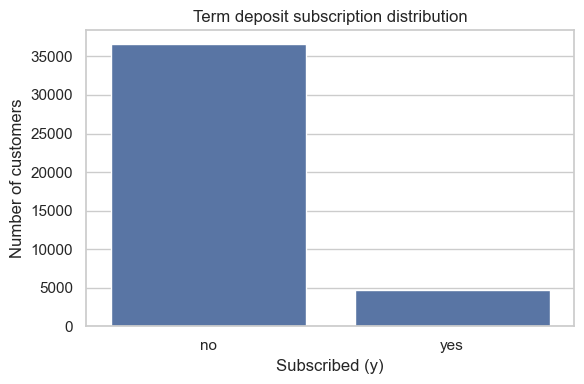

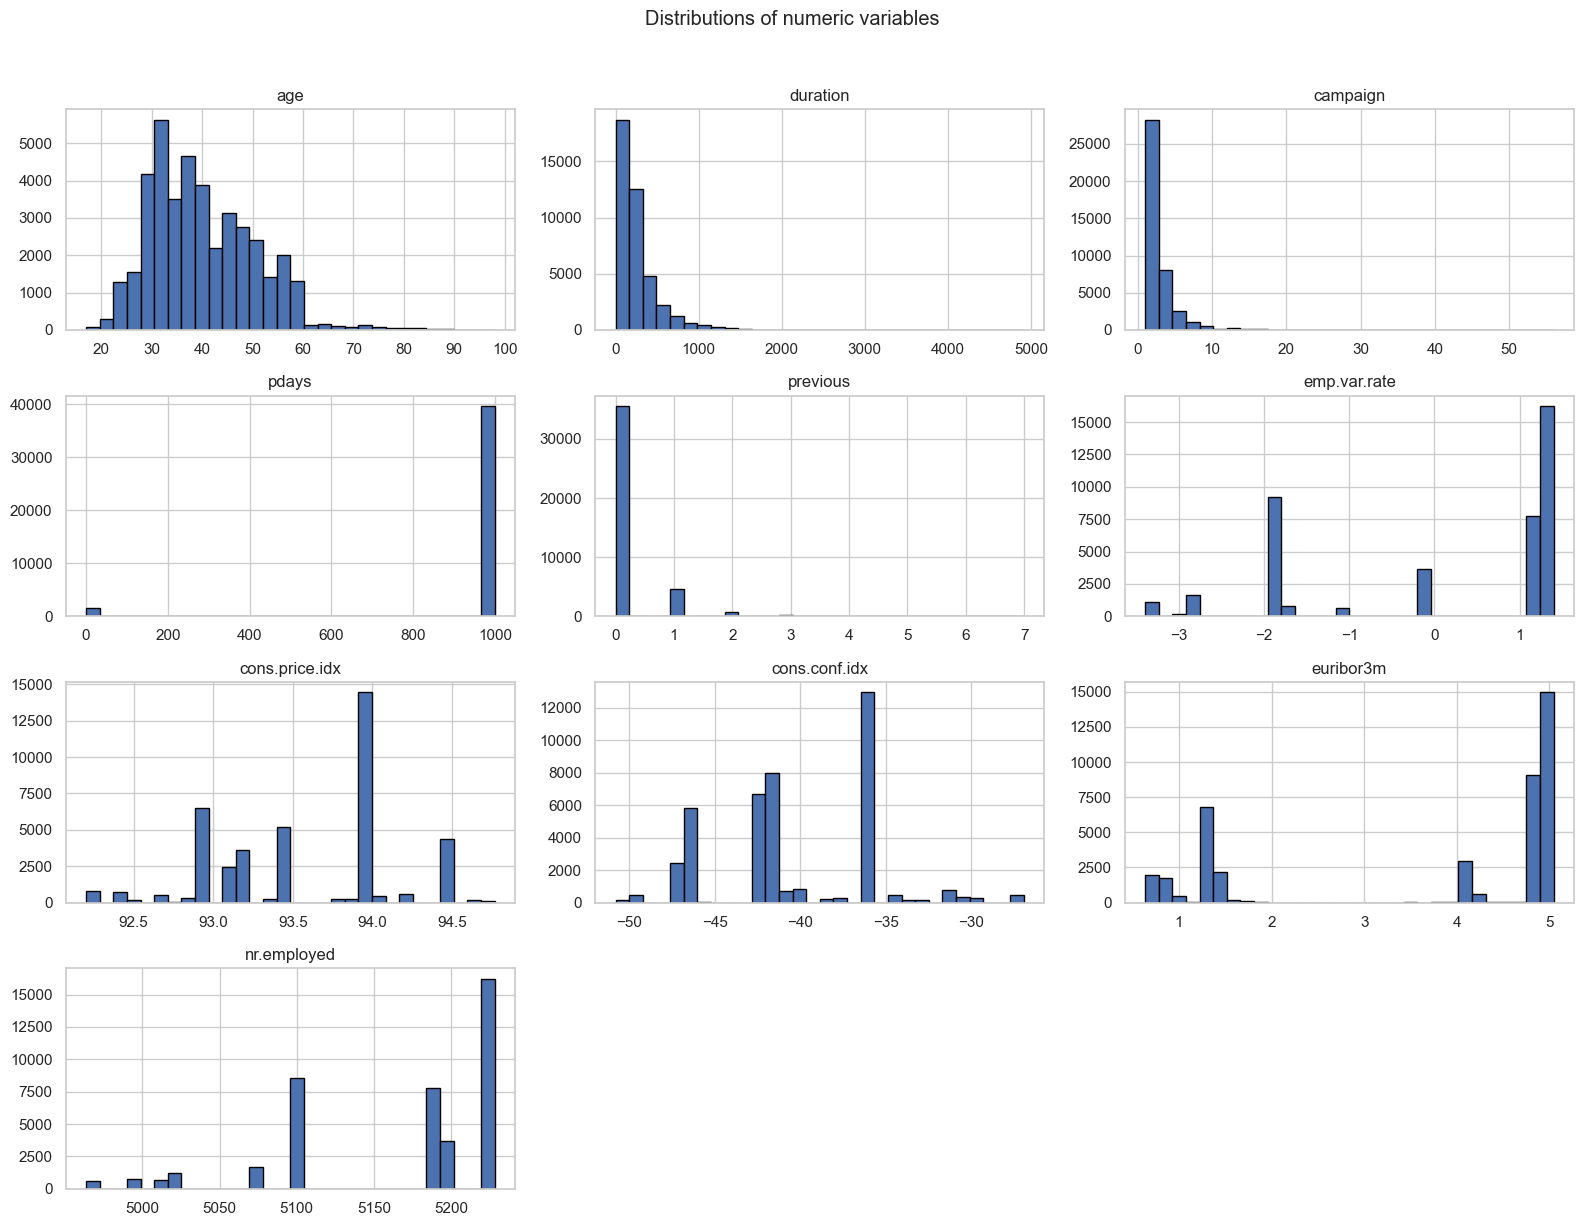

In [41]:
# Target distribution
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x="y", order=df["y"].value_counts().index)
plt.title("Term deposit subscription distribution")
plt.xlabel("Subscribed (y)")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

# Numeric feature distributions
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
df[numeric_cols].hist(figsize=(16, 12), bins=30, edgecolor="black")
plt.suptitle("Distributions of numeric variables", y=1.02)
plt.tight_layout()
plt.show()

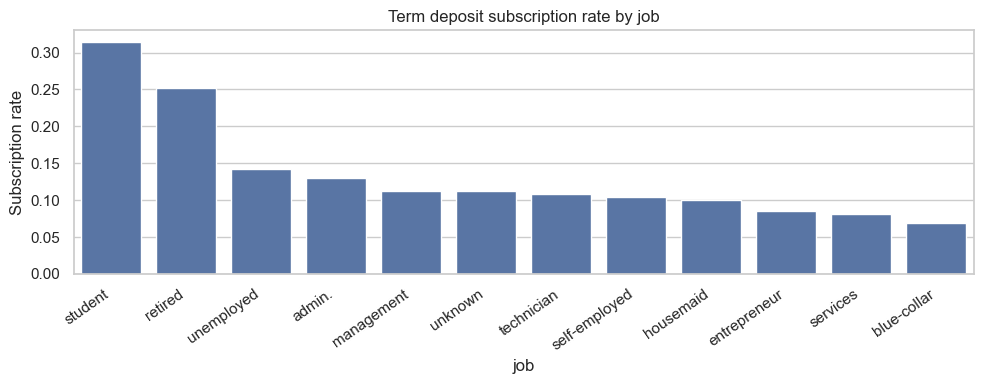

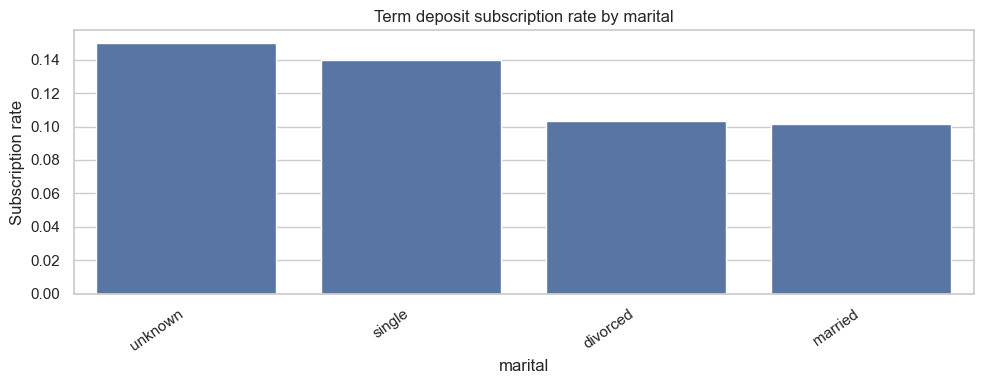

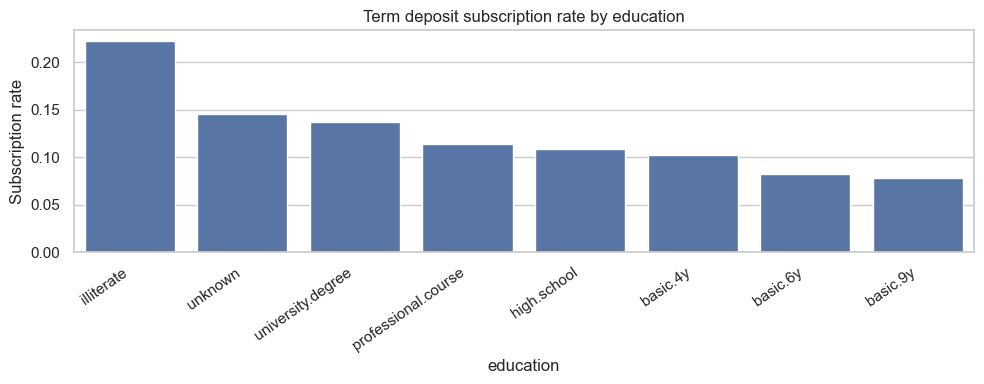

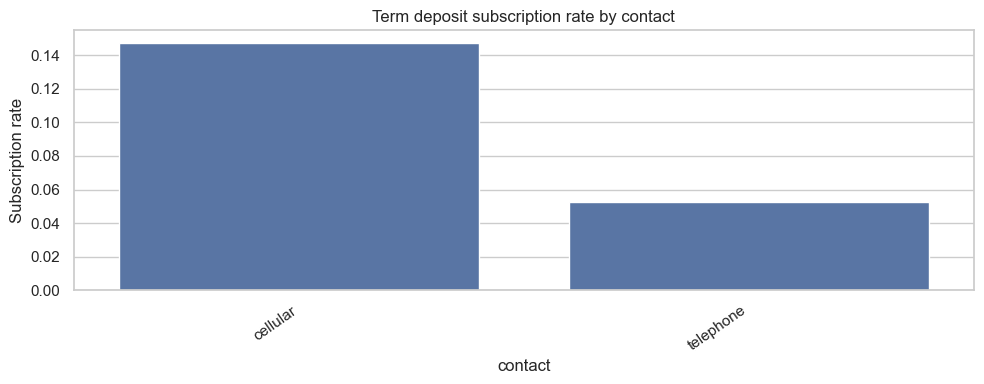

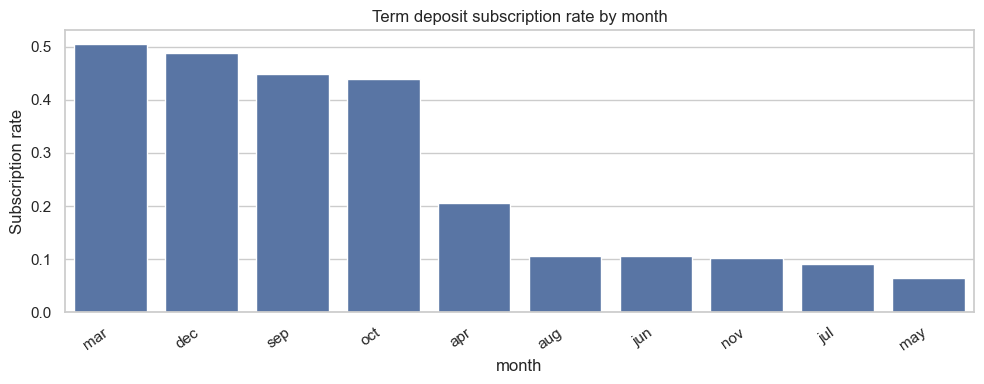

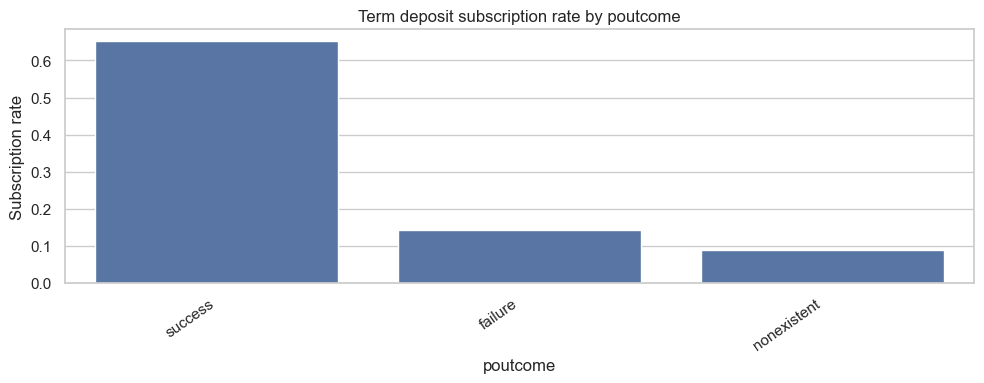

In [42]:
# Subscription rate by selected categorical variables
categorical_cols = df.select_dtypes(include=["object", "category"]).columns.drop("y").tolist()
selected_cats = [c for c in ["job", "marital", "education", "contact", "month", "poutcome"] if c in df.columns]

for col in selected_cats:
    rate = df.groupby(col, dropna=False)["y"].apply(lambda s: (s == "yes").mean()).sort_values(ascending=False)
    plt.figure(figsize=(10, 4))
    sns.barplot(x=rate.index.astype(str), y=rate.values)
    plt.title(f"Term deposit subscription rate by {col}")
    plt.ylabel("Subscription rate")
    plt.xlabel(col)
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()

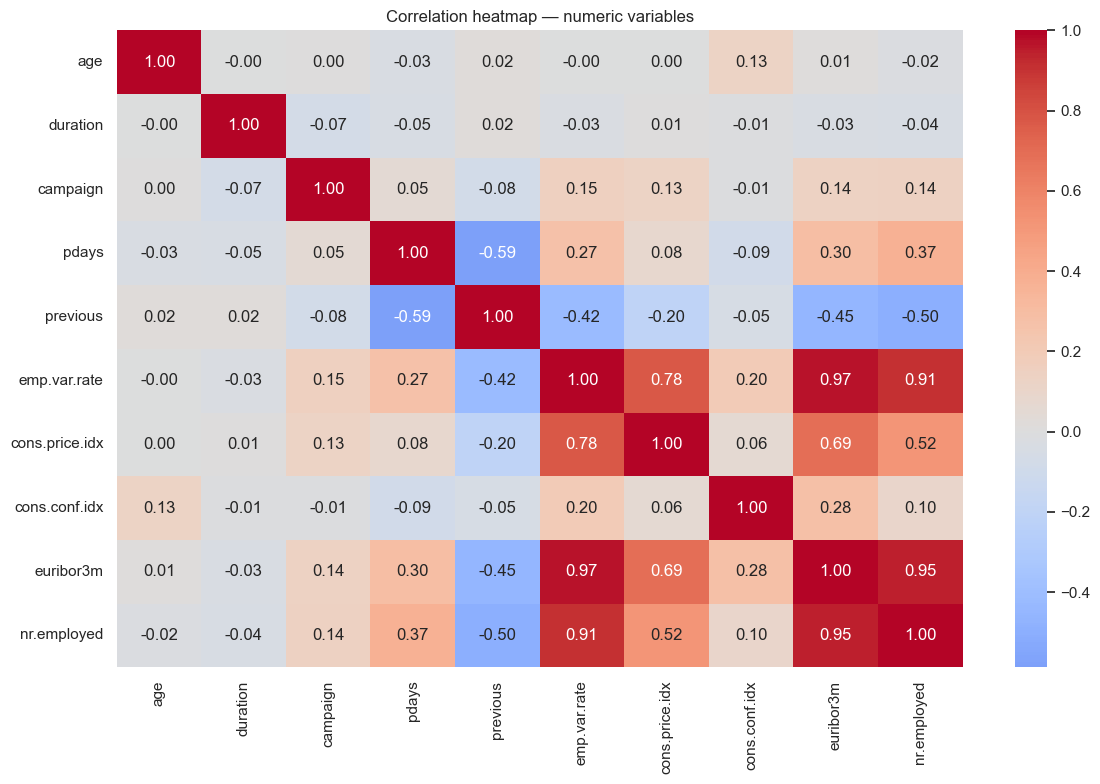

In [43]:
# Correlation heatmap for numeric variables
plt.figure(figsize=(12, 8))
sns.heatmap(df[numeric_cols].corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f")
plt.title("Correlation heatmap — numeric variables")
plt.tight_layout()
plt.show()

## 5. Key observations (data-driven)

In [44]:
target_rate = (df["y"].eq("yes").mean() * 100)
print(f"Overall subscription rate: {target_rate:.2f}%")
print(f"Class imbalance ratio (no / yes): {df['y'].value_counts()['no'] / df['y'].value_counts()['yes']:.2f}")

for col in selected_cats:
    summary = (df.groupby(col)["y"]
                 .apply(lambda s: (s == "yes").mean() * 100)
                 .sort_values(ascending=False))
    print(f"\n{col}: highest observed subscription-rate categories")
    display(summary.head(5).round(2).rename("subscription_rate_percent").to_frame())

Overall subscription rate: 11.27%
Class imbalance ratio (no / yes): 7.88

job: highest observed subscription-rate categories


,subscription_rate_percent
job,
student,31.43
retired,25.23
unemployed,14.20
admin.,12.97
management,11.22



marital: highest observed subscription-rate categories


,subscription_rate_percent
marital,
unknown,15.00
single,14.00
divorced,10.32
married,10.16



education: highest observed subscription-rate categories


,subscription_rate_percent
education,
illiterate,22.22
unknown,14.50
university.degree,13.72
professional.course,11.35
high.school,10.84


... (2 outputs left out)


month: highest observed subscription-rate categories


,subscription_rate_percent
month,
mar,50.55
dec,48.90
sep,44.91
oct,43.87
apr,20.48



poutcome: highest observed subscription-rate categories


,subscription_rate_percent
poutcome,
success,65.11
failure,14.23
nonexistent,8.83


## 6. Data preparation and leakage prevention

- The target is `y` (`yes` / `no`).
- `duration` is deliberately removed from the production feature set because it is only known after the call. Including it would make a pre-call model unrealistic.
- `pdays = 999` is retained as the dataset's special code meaning the customer was not previously contacted.
- Categorical variables are one-hot encoded.
- Numeric variables are median-imputed and standardized for Logistic Regression.
- Categorical variables are imputed with the most frequent value (if any) and one-hot encoded.
- A stratified train/test split preserves the target class proportions.

In [45]:
TARGET = "y"
LEAKAGE_COLUMN = "duration"
X = df.drop(columns=[TARGET, LEAKAGE_COLUMN])
y = df[TARGET].map({"no": 0, "yes": 1})

numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Features used:", X.shape[1])
print("Excluded leakage column:", LEAKAGE_COLUMN)
print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)
print("Train shape:", X_train.shape, "| Test shape:", X_test.shape)
print("Train positive rate:", round(y_train.mean() * 100, 2), "%")
print("Test positive rate:", round(y_test.mean() * 100, 2), "%")

Features used: 19
Excluded leakage column: duration
Numeric features: ['age', 'campaign', 'pdays', 'previous', 'emp.var.rate', 'cons.price.idx', 'cons.conf.idx', 'euribor3m', 'nr.employed']
Categorical features: ['job', 'marital', 'education', 'default', 'housing', 'loan', 'contact', 'month', 'day_of_week', 'poutcome']
Train shape: (32950, 19) | Test shape: (8238, 19)
Train positive rate: 11.27 %
Test positive rate: 11.26 %


## 7. Build preprocessing and candidate models

In [46]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=12, min_samples_leaf=20, class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced_subsample",
        n_jobs=-1, random_state=RANDOM_STATE
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300, min_samples_leaf=5, class_weight="balanced",
        n_jobs=-1, random_state=RANDOM_STATE
    )
}

pipelines = {
    name: Pipeline(steps=[("preprocessor", preprocessor), ("model", estimator)])
    for name, estimator in models.items()
}
print("Candidate models:", list(pipelines))

Candidate models: ['Logistic Regression', 'Decision Tree', 'Random Forest', 'Extra Trees']


## 8. Train and compare models

In [ ]:
results = []
fitted_models = {}

for name, pipeline in pipelines.items():
    print(f"Training {name}...")
    pipeline.fit(X_train, y_train)
    fitted_models[name] = pipeline

    pred = pipeline.predict(X_test)
    proba = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, pred),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1": f1_score(y_test, pred, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, proba),
        "PR_AUC": average_precision_score(y_test, proba)
    })

comparison = pd.DataFrame(results).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
display(comparison.style.format({c: "{:.4f}" for c in comparison.columns if c != "Model"}))

Training Logistic Regression...


In [ ]:
# Visual model comparison
for metric in ["PR_AUC", "ROC_AUC", "Recall", "Precision", "F1"]:
    plt.figure(figsize=(9, 4))
    sns.barplot(data=comparison, x="Model", y=metric)
    plt.title(f"Model comparison — {metric}")
    plt.xticks(rotation=20, ha="right")
    plt.ylim(0, 1)
    plt.tight_layout()
    plt.show()

## 9. Select the production candidate and evaluate it

In [ ]:
# PR-AUC is used as the primary ranking metric because the positive class is the minority class.
best_model_name = comparison.iloc[0]["Model"]
best_model = fitted_models[best_model_name]
best_probability = best_model.predict_proba(X_test)[:, 1]
best_prediction = (best_probability >= 0.50).astype(int)

print("Selected candidate:", best_model_name)
print("\nClassification report at threshold 0.50:")
print(classification_report(y_test, best_prediction, target_names=["No", "Yes"], zero_division=0))

cm = confusion_matrix(y_test, best_prediction)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted No", "Predicted Yes"],
            yticklabels=["Actual No", "Actual Yes"])
plt.title(f"Confusion matrix — {best_model_name}")
plt.tight_layout()
plt.show()

RocCurveDisplay.from_predictions(y_test, best_probability)
plt.title(f"ROC curve — {best_model_name}")
plt.tight_layout()
plt.show()

PrecisionRecallDisplay.from_predictions(y_test, best_probability)
plt.title(f"Precision-recall curve — {best_model_name}")
plt.tight_layout()
plt.show()

## 10. Threshold analysis

The default threshold of 0.50 is not automatically optimal for a marketing campaign. A lower threshold may identify more likely subscribers (higher recall) but can also increase the number of calls to customers who do not subscribe. Choose the threshold based on campaign capacity and the relative cost of missed subscribers versus unnecessary calls.

In [ ]:
threshold_rows = []
for threshold in np.arange(0.10, 0.91, 0.05):
    pred_t = (best_probability >= threshold).astype(int)
    threshold_rows.append({
        "threshold": round(float(threshold), 2),
        "precision": precision_score(y_test, pred_t, zero_division=0),
        "recall": recall_score(y_test, pred_t, zero_division=0),
        "f1": f1_score(y_test, pred_t, zero_division=0),
        "customers_flagged": int(pred_t.sum())
    })
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(3))
threshold_table.set_index("threshold")[["precision", "recall", "f1"]].plot(figsize=(9, 5), marker="o")
plt.title("Precision, recall and F1 by decision threshold")
plt.ylabel("Score")
plt.tight_layout()
plt.show()

## 11. Explain the selected model

In [ ]:
# Permutation importance on the held-out test set. This works with the complete pipeline.
# It measures the drop in PR-AUC when one input feature is shuffled.
perm = permutation_importance(
    best_model, X_test, y_test, scoring="average_precision",
    n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1
)
importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance.head(15).round(5))
plt.figure(figsize=(9, 6))
top_imp = importance.head(15).sort_values("importance_mean")
plt.barh(top_imp["feature"], top_imp["importance_mean"], xerr=top_imp["importance_std"])
plt.title("Top 15 permutation feature importances")
plt.xlabel("Decrease in PR-AUC after permutation")
plt.tight_layout()
plt.show()

## 12. Business recommendations for the bank marketing team

Use the EDA charts and measured model outputs above to prioritize the following actions:

1. **Prioritize rather than mass-contact:** Rank customers by predicted subscription probability and start with the highest-scoring group, subject to campaign capacity.
2. **Choose an operating threshold with the campaign team:** Use the threshold table to understand the precision/recall trade-off. Estimate the cost of a call, the value of a term deposit, and the acceptable missed-opportunity rate before choosing a cutoff.
3. **Use relevant customer segments:** Review the subscription-rate charts by job, education, month, contact channel, and previous campaign outcome. Tailor messaging and scheduling only where the observed rates support it.
4. **Use previous campaign outcomes carefully:** Customers with a previous successful campaign outcome may be a useful segment to investigate; validate the effect in the model and with a controlled campaign test.
5. **Avoid over-contacting:** Review `campaign` and contact history when designing contact-frequency limits. Test whether fewer repeated contacts can preserve conversions while improving customer experience.
6. **Run an A/B test:** Compare model-prioritized outreach against the existing selection approach. Track conversion rate, cost per subscription, complaints/unsubscribes, and incremental profit.
7. **Monitor performance:** Track precision, recall, PR-AUC, conversion rate, and drift by month. Retrain when customer behaviour or economic conditions change.

These are recommendations to validate operationally, not claims that every segment or tactic will cause higher conversion.

## 13. Challenges faced and techniques used

| Challenge | Technique used | Reason |
|---|---|---|
| Target class imbalance (`no` is much more common than `yes`) | Stratified split, class weights, PR-AUC and recall/precision reporting | Accuracy alone can hide poor identification of subscribers. |
| Categorical features | One-hot encoding with `handle_unknown='ignore'` | Models require numeric inputs and new categories should not break inference. |
| Missing values / robustness | Median imputation for numeric and most-frequent imputation for categorical inputs | Keeps the pipeline usable if missing values occur in future data. |
| Leakage from `duration` | Excluded from production features | Duration is only known after the phone call, so it cannot support pre-call targeting. |
| Special code `pdays=999` | Retained and documented | The source defines 999 as “not previously contacted”; it is meaningful dataset information. |
| Different model scales and behaviours | Shared preprocessing pipeline and held-out test set | Makes candidate model comparison consistent. |
| Marketing trade-off between missed subscribers and unnecessary calls | Threshold analysis | The best cutoff depends on campaign economics and team capacity. |

Additional practical considerations before production: validate on a later time period, assess calibration, monitor drift, review fairness and customer-contact rules, and test campaign uplift experimentally.

## 14. Save the model and supporting outputs

In [ ]:
OUTPUT_DIR = BASE_DIR / "portuguese_bank_outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

model_path = OUTPUT_DIR / "best_portuguese_bank_model.joblib"
joblib.dump({
    "pipeline": best_model,
    "feature_columns": X.columns.tolist(),
    "target_mapping": {"no": 0, "yes": 1},
    "excluded_columns": [LEAKAGE_COLUMN],
    "selected_model": best_model_name
}, model_path)

comparison.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)
importance.to_csv(OUTPUT_DIR / "permutation_feature_importance.csv", index=False)
threshold_table.to_csv(OUTPUT_DIR / "threshold_analysis.csv", index=False)

print("Saved model:", model_path)
print("Saved reports in:", OUTPUT_DIR.resolve())

## 15. Example: score new customers

In [ ]:
# Example uses a few existing test rows only to demonstrate the inference interface.
# In real use, provide a new DataFrame with the same input columns as X (without y or duration).
example_customers = X_test.head(5).copy()
example_scores = best_model.predict_proba(example_customers)[:, 1]

scored_customers = example_customers.copy()
scored_customers["predicted_subscription_probability"] = example_scores
scored_customers["predicted_subscription_at_0_50"] = np.where(example_scores >= 0.50, "yes", "no")
display(scored_customers)

## 16. Final conclusion

This notebook completes the requested analysis, builds and compares four classification models, evaluates the leading candidate using minority-class-aware metrics, explains the decision threshold trade-off, and provides marketing recommendations and a challenge log.

**Production reminder:** The model is a candidate, not an automatic deployment approval. Before launch, test it on a later time-based holdout, validate probability calibration, assess fairness and regulatory requirements, and run a controlled campaign experiment. The production model must continue to exclude `duration`.